# Generative refinement of the blended midpoint: conditional flow matching vs L1 regression

Pipeline of the first notebook (frozen RAFT-small, forward splat, learned blending mask) is the **baseline**.
It closed ~13 % of the oracle gap in `dis`; the remaining error is content neither warp contains
(disocclusions, blur), where any regression outputs the conditional mean. This notebook adds a refiner of
the residual `target - blend`, trained on crops centred on `dis`, in two modes with the **same U-Net**:

- `fm`: rectified-flow / flow matching, `x_t = (1-t) x0 + t x1`, net predicts `x1 - x0`, Euler sampling (generative);
- `l1`: same net, no noise, predicts the residual directly (regression control).

Methods on test: `fixed`, `learned` (= blend), `l1`, `l1_dis` (residual applied inside `dis` only), `fm` (one sample),
`fm_dis`, `fm_mean` (mean of `FM_MEAN_SAMPLES` samples), `oracle`. Metrics: pooled PSNR by region with triplet
bootstrap, paired full-frame PSNR, **LPIPS** (alex) on the full frame and on the 128x128 window with the most `dis`.

**Predictions written before the run.** `l1`: PSNR in `dis` up by 0.3-0.8 dB vs `learned`, LPIPS slightly down.
`fm` (one sample): PSNR in `dis` at or below `l1`, possibly below `learned`; LPIPS on the dis window the lowest of all.
`fm_mean`: PSNR between `fm` and `l1`, LPIPS worse than `fm` (averaging samples turns a generative model back into
a regressor). `fm_dis` vs `fm`: residual outside `dis` should be ~0; if `fm_dis` beats `fm` on PSNR, the sampler
hallucinates where it should not.

Kaggle: **T4, Internet ON**. Attach the output of the first run as input if you want to skip mask training
(`mask_best.pt` is picked up automatically from `/kaggle/input`). Run `SMOKE = True` first.
Budget: flows 1 min, mask 10 min (or 0), two refiners ~10 min each, test on 1 000 triplets with
sampling ~12 min, LPIPS included.

In [13]:
from pathlib import Path
SMOKE = False            # True: 16 synthetic triplets, 60 steps, runs on CPU. Do this first.
N_TRAIN, N_VAL = 1200, 150
TEST_LIMIT = 1000        # sampling is the cost here; None = all 3782 (~45 min of test pass)
STEPS, BATCH, CROP, LR, LAMBDA_DIS = 8000, 8, 192, 1e-3, 4.0
EVAL_EVERY, CKPT_EVERY = 1000, 500
HEUR_S = 1.0             # heuristic strength; 0.5/1/2 grid on val below
SEED = 42
RESUME = True            # continue from work/ckpt_latest.pt if the session was interrupted
WORK = Path("/kaggle/working") if Path("/kaggle").exists() else Path("./work")
WORK.mkdir(parents=True, exist_ok=True)
REFINERS = ("l1", "fm")
FM_STEPS, FM_BATCH, FM_CROP, LR_FM = 12000, 16, 96, 2e-4
FM_EVAL_EVERY, FM_CKPT_EVERY = 2000, 500
FM_SAMPLE_STEPS, FM_MEAN_SAMPLES = 20, 4
if SMOKE:
    N_TRAIN, N_VAL, TEST_LIMIT, STEPS, EVAL_EVERY, CKPT_EVERY, BATCH = 12, 4, 4, 60, 20, 30, 4
    FM_STEPS, FM_BATCH, FM_EVAL_EVERY, FM_CKPT_EVERY, FM_SAMPLE_STEPS, FM_MEAN_SAMPLES = 40, 4, 20, 20, 4, 2

In [14]:
import os, math, time, json, random, zlib
from itertools import groupby, islice
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display
from torchvision.models.optical_flow import raft_small, Raft_Small_Weights
try:
    import lpips
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lpips'], check=True)
    import lpips

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # MPS on purpose excluded: index_add_ bugs on macOS 14
print("device", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 1.1 MB/s eta 0:00:00
device cuda Tesla T4


## Core: splat, occlusion maps, heuristic, features, mask U-Net, region metrics

In [15]:
"""Core of the evening experiment: forward splat to the midpoint grid, occlusion maps,
heuristic mask with the correct sign, features on the t-grid, a small mask U-Net,
region metrics with a triplet bootstrap. Pure torch, CPU/CUDA; no gradients through warps.
Coordinates: flow in pixels, (x, y) = (channel 0, channel 1); grid 0 / grid 1 / grid t.
"""
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# ----------------------------------------------------------------------------- warps

def backward_warp(img, flow):
    """Sample img at p + flow(p). img [B,C,H,W], flow [B,2,H,W] px. Border padding."""
    B, C, H, W = img.shape
    yy, xx = torch.meshgrid(
        torch.arange(H, device=img.device, dtype=img.dtype),
        torch.arange(W, device=img.device, dtype=img.dtype), indexing="ij")
    gx = 2.0 * (xx[None] + flow[:, 0]) / max(W - 1, 1) - 1.0
    gy = 2.0 * (yy[None] + flow[:, 1]) / max(H - 1, 1) - 1.0
    grid = torch.stack((gx, gy), dim=-1)
    return F.grid_sample(img, grid, mode="bilinear", padding_mode="border", align_corners=True)


def fb_occlusion(f_fwd, f_bwd, a1=0.01, a2=0.5):
    """UnFlow forward-backward check on the grid of f_fwd. 1 = no correspondence in the other frame."""
    fb = backward_warp(f_bwd, f_fwd)
    diff = (f_fwd + fb).square().sum(1, keepdim=True)
    mag = f_fwd.square().sum(1, keepdim=True) + fb.square().sum(1, keepdim=True)
    return (diff > a1 * mag + a2).to(f_fwd.dtype)


def splat(values, flow, importance=None):
    """Forward bilinear splat of values from the source grid to p + flow.
    values [B,C,H,W], flow [B,2,H,W] px, importance [B,1,H,W] > 0 (collision weights).
    Returns num [B,C,H,W], den [B,1,H,W] (sum importance*bilinear), cnt [B,1,H,W] (sum bilinear)."""
    B, C, H, W = values.shape
    dev, dt = values.device, values.dtype
    if importance is None:
        importance = torch.ones(B, 1, H, W, device=dev, dtype=dt)
    yy, xx = torch.meshgrid(torch.arange(H, device=dev, dtype=dt),
                            torch.arange(W, device=dev, dtype=dt), indexing="ij")
    x = xx[None] + flow[:, 0]
    y = yy[None] + flow[:, 1]
    x0, y0 = x.floor(), y.floor()
    pack = torch.cat([values * importance, importance, torch.ones_like(importance)], 1)  # [B,C+2,H,W]
    K = C + 2
    out = torch.zeros(K, B * H * W, device=dev, dtype=dt)
    boff = (torch.arange(B, device=dev) * H * W)[:, None, None]
    for dx in (0, 1):
        for dy in (0, 1):
            xi, yi = x0 + dx, y0 + dy
            w = (1 - (x - xi).abs()).clamp(min=0) * (1 - (y - yi).abs()).clamp(min=0)
            valid = (xi >= 0) & (xi < W) & (yi >= 0) & (yi < H)
            w = w * valid
            idx = (yi.clamp(0, H - 1) * W + xi.clamp(0, W - 1)).long() + boff  # [B,H,W]
            out.index_add_(1, idx.reshape(-1), (pack * w[:, None]).permute(1, 0, 2, 3).reshape(K, -1))
    out = out.view(K, B, H, W).permute(1, 0, 2, 3)
    return out[:, :C], out[:, C:C + 1], out[:, C + 1:C + 2]


@torch.no_grad()
def make_warps(a, b, f01, f10, alpha=10.0, hole_thr=0.3):
    """Both frames splatted to the midpoint grid. Collisions weighted by brightness-constancy
    importance exp(-alpha*err). Holes (coverage < hole_thr) filled with the old backward half-flow warp.
    Returns dict on grid t: w0 w1 f01_t f10_t o0_t o1_t hole0 hole1 cnt0 cnt1."""
    f01, f10 = f01.float(), f10.float()
    err0 = (a - backward_warp(b, f01)).abs().mean(1, keepdim=True)
    err1 = (b - backward_warp(a, f10)).abs().mean(1, keepdim=True)
    o0 = fb_occlusion(f01, f10)
    o1 = fb_occlusion(f10, f01)
    num0, den0, cnt0 = splat(torch.cat([a, f01, o0], 1), 0.5 * f01, torch.exp(-alpha * err0))
    num1, den1, cnt1 = splat(torch.cat([b, f10, o1], 1), 0.5 * f10, torch.exp(-alpha * err1))
    s0 = num0 / den0.clamp_min(1e-8)
    s1 = num1 / den1.clamp_min(1e-8)
    hole0 = (cnt0 < hole_thr).float()
    hole1 = (cnt1 < hole_thr).float()
    h0, h1 = hole0.bool(), hole1.bool()
    w0 = torch.where(h0, backward_warp(a, -0.5 * f01), s0[:, :3])
    w1 = torch.where(h1, backward_warp(b, -0.5 * f10), s1[:, :3])
    return dict(
        w0=w0, w1=w1,
        f01_t=torch.where(h0, f01, s0[:, 3:5]), f10_t=torch.where(h1, f10, s1[:, 3:5]),
        o0_t=torch.where(h0, torch.zeros_like(hole0), s0[:, 5:6]),
        o1_t=torch.where(h1, torch.zeros_like(hole1), s1[:, 5:6]),
        hole0=hole0, hole1=hole1, cnt0=cnt0, cnt1=cnt1)


# ----------------------------------------------------------------------------- masks

def heuristic_mask_raw(Wd, s=1.0):
    """Before hole override. o0_t = pixel came from frame 0 and has no match in frame 1 -> trust w0 -> M up."""
    return (0.5 + 0.5 * s * (Wd["o0_t"] - Wd["o1_t"])).clamp(0, 1)


def heuristic_mask(Wd, s=1.0):
    m = heuristic_mask_raw(Wd, s)
    m = torch.where(Wd["hole0"].bool(), torch.zeros_like(m), m)   # nothing from frame 0 here -> w1
    m = torch.where(Wd["hole1"].bool(), torch.ones_like(m), m)    # nothing from frame 1 here -> w0
    return m


def blend(Wd, m):
    return m * Wd["w0"] + (1 - m) * Wd["w1"]


def oracle_alpha(Wd, target):
    """Per-pixel least-squares alpha in [0,1] using the target. Upper bound, not a method."""
    d = Wd["w0"] - Wd["w1"]
    r = target - Wd["w1"]
    return ((d * r).sum(1, keepdim=True) / d.square().sum(1, keepdim=True).clamp_min(1e-8)).clamp(0, 1)


def shuffled_alpha(alpha):
    """Null: oracle alpha of another triplet (roll along batch; mirror when batch is 1)."""
    return alpha.roll(1, dims=0) if alpha.shape[0] > 1 else alpha.flip(-1)


FLOW_SCALE = 20.0
FEAT_X_CHANNELS = (9, 11)   # x-components of f01_t, f10_t: negate on horizontal flip


def make_features(Wd):
    """18 channels on grid t."""
    return torch.cat([
        Wd["w0"], Wd["w1"], (Wd["w0"] - Wd["w1"]).abs(),
        Wd["f01_t"] / FLOW_SCALE, Wd["f10_t"] / FLOW_SCALE,
        Wd["o0_t"], Wd["o1_t"], Wd["hole0"], Wd["hole1"],
        heuristic_mask(Wd)], 1)


def dis_region(Wd, tau=0.04):
    """Where the two warps disagree: the only place a blending mask can act. Method-independent."""
    return ((Wd["w0"] - Wd["w1"]).abs().mean(1, keepdim=True) > tau).float()


def occ_region(Wd):
    return (((Wd["o0_t"] + Wd["o1_t"]) > 0.5) | Wd["hole0"].bool() | Wd["hole1"].bool()).float()


# ----------------------------------------------------------------------------- net

def _block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1), nn.ReLU(inplace=True))


class MaskUNet(nn.Module):
    """3-level U-Net, ~95k params. Last conv zero-init -> starts at exactly 0.5 (= fixed blend)."""
    def __init__(self, in_ch=18, w=(16, 32, 48)):
        super().__init__()
        self.e1 = _block(in_ch, w[0])
        self.e2 = _block(w[0], w[1])
        self.e3 = _block(w[1], w[2])
        self.d2 = _block(w[2] + w[1], w[1])
        self.d1 = _block(w[1] + w[0], w[0])
        self.out = nn.Conv2d(w[0], 1, 3, padding=1)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)

    def forward(self, x):
        H, W = x.shape[-2:]
        ph, pw = (-H) % 4, (-W) % 4
        x = F.pad(x, (0, pw, 0, ph), mode="replicate")
        e1 = self.e1(x)
        e2 = self.e2(F.avg_pool2d(e1, 2))
        e3 = self.e3(F.avg_pool2d(e2, 2))
        d2 = self.d2(torch.cat([F.interpolate(e3, scale_factor=2, mode="bilinear", align_corners=False), e2], 1))
        d1 = self.d1(torch.cat([F.interpolate(d2, scale_factor=2, mode="bilinear", align_corners=False), e1], 1))
        return torch.sigmoid(self.out(d1))[..., :H, :W]


def hflip_features(feat):
    feat = feat.flip(-1)
    for c in FEAT_X_CHANNELS:
        feat[:, c] = -feat[:, c]
    return feat


# ----------------------------------------------------------------------------- metrics

REGIONS = ("full", "dis", "occ")


@torch.no_grad()
def region_sse(preds, target, regions):
    """preds: dict name -> [B,3,H,W]; regions: dict name -> [B,1,H,W] in {0,1}.
    Returns rows: (b, method, region, sse, n) with n = number of RGB values in the region."""
    rows = []
    B = target.shape[0]
    for rname, rm in regions.items():
        n = rm.sum(dim=(1, 2, 3)) * 3
        for mname, p in preds.items():
            se = ((p.clamp(0, 1) - target).square() * rm).sum(dim=(1, 2, 3))
            for i in range(B):
                rows.append((i, mname, rname, float(se[i]), float(n[i])))
    return rows


def pooled_mse(df, method, region):
    d = df[(df.method == method) & (df.region == region)]
    return d.sse.sum() / max(d.n.sum(), 1.0)


def bootstrap_region(df, region, methods, ref="fixed", oracle="oracle", n_boot=2000, seed=0):
    """Triplet bootstrap of delta dB vs ref and gap-closed fraction G vs oracle.
    df columns: key, method, region, sse, n. Returns dict method -> (point, lo, hi) for 'db' and 'G'."""
    sub = df[df.region == region]
    keys = sorted(sub.key.unique())
    piv_sse = sub.pivot_table(index="key", columns="method", values="sse", aggfunc="sum").loc[keys]
    piv_n = sub.pivot_table(index="key", columns="method", values="n", aggfunc="sum").loc[keys]
    S = piv_sse.to_numpy()
    N = piv_n[ref].to_numpy()
    cols = list(piv_sse.columns)
    rng = np.random.default_rng(seed)
    T = len(keys)
    idx = np.vstack([np.arange(T)[None], rng.integers(0, T, size=(n_boot, T))])  # row 0 = point estimate

    def stats(ix):
        s = S[ix].sum(0)
        n = N[ix].sum()
        mse = {c: s[j] / max(n, 1.0) for j, c in enumerate(cols)}
        out = {}
        for m in methods:
            db = 10 * math.log10(max(mse[ref], 1e-12) / max(mse[m], 1e-12))
            gap = mse[ref] - mse.get(oracle, 0.0)
            G = (mse[ref] - mse[m]) / gap if gap > 1e-12 else float("nan")
            out[m] = (db, G)
        return out

    all_stats = [stats(ix) for ix in idx]
    res = {}
    for m in methods:
        dbs = np.array([s[m][0] for s in all_stats])
        Gs = np.array([s[m][1] for s in all_stats])
        res[m] = {
            "db": (dbs[0], np.percentile(dbs[1:], 2.5), np.percentile(dbs[1:], 97.5)),
            "G": (Gs[0], np.nanpercentile(Gs[1:], 2.5), np.nanpercentile(Gs[1:], 97.5)),
        }
    return res


def psnr_from_mse(mse):
    return -10 * math.log10(max(mse, 1e-12))

## Data: train/val from the HF stream, test = official Vimeo-90K test (3 782 triplets)

In [16]:
def to_u8(img):
    return np.asarray(img.convert("RGB"), dtype=np.uint8)

def synth_triplet(seed, H=256, W=448, S=64):
    g = torch.Generator().manual_seed(seed)
    bg = F.avg_pool2d(torch.rand(1, 3, H, W, generator=g), 3, 1, 1)[0]
    sq = F.avg_pool2d(torch.rand(1, 3, S, S, generator=g), 3, 1, 1)[0] * 0.5 + 0.5
    d = int(torch.randint(4, 24, (1,), generator=g)) * 2
    x0, y0 = int(torch.randint(10, W - S - d - 10, (1,), generator=g)), int(torch.randint(10, H - S - 10, (1,), generator=g))
    out = []
    for x in (x0, x0 + d // 2, x0 + d):
        f = bg.clone(); f[:, y0:y0 + S, x:x + S] = sq
        out.append((f.permute(1, 2, 0).numpy() * 255).astype(np.uint8))
    return np.stack(out)

if SMOKE:
    train_u8 = np.stack([synth_triplet(i) for i in range(N_TRAIN + N_VAL)])
    test_get = lambda i: synth_triplet(1000 + i)
    N_TEST = TEST_LIMIT
    test_keys = [f"synth{i}" for i in range(N_TEST)]
else:
    from datasets import load_dataset
    ds = load_dataset("danjacobellis/vimeo90k_triplet", split="train", streaming=True)
    frames, bad = [], 0
    for label, rows in tqdm(groupby(ds, key=lambda r: r["label"]), total=N_TRAIN + N_VAL, desc="train stream"):
        rows = list(islice(rows, 4))
        if len(rows) != 3:
            bad += 1; continue
        frames.append(np.stack([to_u8(r["image"]) for r in rows]))
        if len(frames) >= N_TRAIN + N_VAL:
            break
    train_u8 = np.stack(frames)
    print(f"train+val triplets {len(train_u8)}, skipped groups {bad}")
    tds = load_dataset("paschalc24/vimeo-90k-test-full")
    tds = tds[list(tds.keys())[0]]
    img_cols = sorted(c for c, f in tds.features.items() if type(f).__name__ == "Image")
    assert len(img_cols) == 3, tds.features
    key_col = next((c for c in tds.column_names if "seq" in c or "id" in c), None)
    test_get = lambda i: np.stack([to_u8(tds[i][c]) for c in img_cols])
    N_TEST = len(tds) if TEST_LIMIT is None else min(TEST_LIMIT, len(tds))
    test_keys = [str(tds[i][key_col]) if key_col else str(i) for i in range(N_TEST)]
    print("test columns", img_cols, "key", key_col, "N_TEST", N_TEST)

assert train_u8.shape[1:] == (3, 256, 448, 3), train_u8.shape
train_u8 = torch.from_numpy(train_u8).permute(0, 1, 4, 2, 3).contiguous()     # [N,3 frames,3 ch,H,W] uint8
val_u8, train_u8 = train_u8[N_TRAIN:N_TRAIN + N_VAL], train_u8[:N_TRAIN]
print("train", tuple(train_u8.shape), "val", tuple(val_u8.shape), "test", N_TEST)

Resolving data files:   0%|          | 0/71 [00:00<?, ?it/s]

train stream:   0%|          | 0/1350 [00:00<?, ?it/s]

train+val triplets 1350, skipped groups 0
test columns ['im1', 'im2', 'im3'] key sequence_id N_TEST 1000
train (1200, 3, 3, 256, 448) val (150, 3, 3, 256, 448) test 1000


## Frozen RAFT-small; flows cached in fp16 for train/val (test flows are computed on the fly)

In [17]:
flow_model = raft_small(weights=Raft_Small_Weights.DEFAULT, progress=False).to(DEVICE).eval()
for p in flow_model.parameters():
    p.requires_grad_(False)
flow_pre = Raft_Small_Weights.DEFAULT.transforms()

@torch.no_grad()
def estimate_flow(x, y):
    B, C, H, W = x.shape
    h8, w8 = H // 8 * 8, W // 8 * 8
    xs = F.interpolate(x, size=(h8, w8), mode="bilinear", align_corners=False) if (h8, w8) != (H, W) else x
    ys = F.interpolate(y, size=(h8, w8), mode="bilinear", align_corners=False) if (h8, w8) != (H, W) else y
    xs, ys = flow_pre(xs, ys)
    flow = flow_model(xs, ys)[-1]
    if (h8, w8) != (H, W):
        flow = F.interpolate(flow, size=(H, W), mode="bilinear", align_corners=False)
        flow[:, 0] *= W / w8; flow[:, 1] *= H / h8
    return flow

def frames_to_float(u8):          # [B,3,3,H,W] uint8 -> a, t, b float on DEVICE
    f = u8.to(DEVICE).float() / 255.0
    return f[:, 0], f[:, 1], f[:, 2]

@torch.no_grad()
def cache_flows(u8, bs=8):
    out = torch.empty(len(u8), 2, 2, u8.shape[-2], u8.shape[-1], dtype=torch.float16)
    for i in tqdm(range(0, len(u8), bs), desc="flows"):
        a, _, b = frames_to_float(u8[i:i + bs])
        out[i:i + bs, 0] = estimate_flow(a, b).half().cpu()
        out[i:i + bs, 1] = estimate_flow(b, a).half().cpu()
    return out

t0 = time.time()
train_flows = cache_flows(train_u8)
val_flows = cache_flows(val_u8)
print(f"flows cached in {time.time()-t0:.0f}s; train cache {train_flows.numel()*2/1e9:.2f} GB")

flows:   0%|          | 0/150 [00:00<?, ?it/s]

flows:   0%|          | 0/19 [00:00<?, ?it/s]

flows cached in 44s; train cache 1.10 GB


## Sanity gate: splatting frame 0 by the full RAFT flow must land close to frame 1

In [18]:
with torch.no_grad():
    a, _, b = frames_to_float(val_u8[:16])
    f01 = val_flows[:16, 0].to(DEVICE).float()
    num, den, cnt = splat(a, f01)
    covered = (cnt > 0.3).float()
    sp = num / den.clamp_min(1e-8)
    mse_sp = (((sp - b) ** 2) * covered).sum() / (covered.sum() * 3)
    mse_id = ((a - b) ** 2).mean()
    gain = 10 * math.log10(mse_id / mse_sp)
print(f"splat(I0, f01) vs I1: {psnr_from_mse(float(mse_sp)):.2f} dB on {float(covered.mean()):.3f} of pixels; "
      f"identity {psnr_from_mse(float(mse_id)):.2f} dB; gain {gain:.2f} dB")
assert gain > 3.0, "splat or flow convention broken: fix before training"

splat(I0, f01) vs I1: 28.89 dB on 0.996 of pixels; identity 24.30 dB; gain 4.58 dB


## Methods, regions, evaluation helpers

In [19]:
METHODS_VS_FIXED = ["old", "heur", "learned", "oracle", "shuf"]

@torch.no_grad()
def run_methods(a, t, b, f01, f10, net=None, heur_s=HEUR_S):
    Wd = make_warps(a, b, f01, f10)
    half = torch.full_like(Wd["hole0"], 0.5)
    preds = {
        "old": 0.5 * backward_warp(a, -0.5 * f01.float()) + 0.5 * backward_warp(b, -0.5 * f10.float()),
        "fixed": blend(Wd, half),
        "heur": blend(Wd, heuristic_mask(Wd, heur_s)),
    }
    masks = {"heur": heuristic_mask(Wd, heur_s)}
    if net is not None:
        net.eval()
        masks["learned"] = net(make_features(Wd))
        preds["learned"] = blend(Wd, masks["learned"])
    al = oracle_alpha(Wd, t)
    preds["oracle"] = blend(Wd, al)
    preds["shuf"] = blend(Wd, shuffled_alpha(al))
    regions = {"full": torch.ones_like(Wd["hole0"]), "dis": dis_region(Wd), "occ": occ_region(Wd)}
    return Wd, preds, masks, regions

@torch.no_grad()
def eval_cached(u8, flows, net=None, bs=8, heur_s=HEUR_S):
    rows = []
    for i in range(0, len(u8), bs):
        a, t, b = frames_to_float(u8[i:i + bs])
        f01, f10 = flows[i:i + bs, 0].to(DEVICE), flows[i:i + bs, 1].to(DEVICE)
        _, preds, _, regions = run_methods(a, t, b, f01, f10, net, heur_s)
        rows += [(i + j, m, r, s, n) for (j, m, r, s, n) in region_sse(preds, t, regions)]
    return pd.DataFrame(rows, columns=["key", "method", "region", "sse", "n"])

def gap_closed(df, method, region="dis"):
    mf, mm, mo = pooled_mse(df, "fixed", region), pooled_mse(df, method, region), pooled_mse(df, "oracle", region)
    return (mf - mm) / max(mf - mo, 1e-12)

## Heuristic strength on val (tiny grid), then the no-training baselines on val

In [20]:
grid = {}
for s in (0.5, 1.0, 2.0):
    d = eval_cached(val_u8, val_flows, None, heur_s=s)
    grid[s] = (gap_closed(d, "heur"), 10 * math.log10(pooled_mse(d, "fixed", "full") / pooled_mse(d, "heur", "full")))
    print(f"s={s}: G_heur(dis)={grid[s][0]:+.3f}  full-frame vs fixed {grid[s][1]:+.3f} dB")
HEUR_S = max(grid, key=lambda s: grid[s][0])
print("HEUR_S =", HEUR_S)
val_base = eval_cached(val_u8, val_flows, None, heur_s=HEUR_S)
for r in REGIONS:
    print(r, {m: f"{psnr_from_mse(pooled_mse(val_base, m, r)):.2f}" for m in ["old", "fixed", "heur", "oracle", "shuf"]})

s=0.5: G_heur(dis)=+0.025  full-frame vs fixed +0.054 dB
s=1.0: G_heur(dis)=-0.006  full-frame vs fixed -0.012 dB
s=2.0: G_heur(dis)=-0.037  full-frame vs fixed -0.075 dB
HEUR_S = 0.5
full {'old': '31.83', 'fixed': '32.72', 'heur': '32.77', 'oracle': '36.31', 'shuf': '31.48'}
dis {'old': '22.65', 'fixed': '23.49', 'heur': '23.57', 'oracle': '29.51', 'shuf': '21.78'}
occ {'old': '26.39', 'fixed': '27.43', 'heur': '27.54', 'oracle': '32.57', 'shuf': '26.03'}


## Training: mask U-Net, weighted L1, crops after full-frame splat, checkpoints every 500 steps

resumed from step 8000


train: 100%|##########| 8000/8000 [00:00<?, ?it/s]

0 ms/step (incl. eval); best val G_learned(dis) +0.084 at step 8000


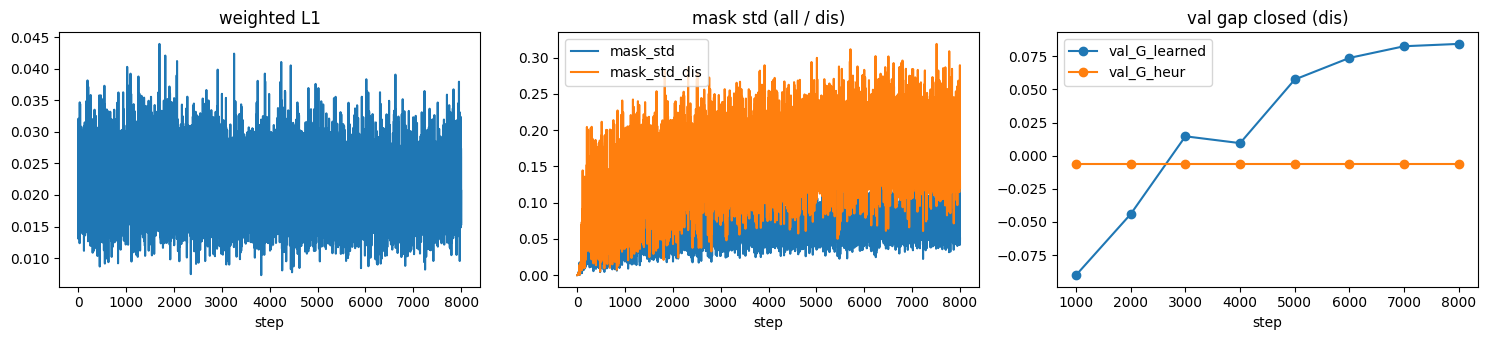

In [21]:
MASK_CKPT = next(Path("/kaggle/input").rglob("mask_best.pt"), None) if Path("/kaggle/input").exists() else None
net = MaskUNet().to(DEVICE)
opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, max(STEPS, 1))
rng = np.random.default_rng(SEED)
history, step, best = [], 0, {"G": -1e9, "step": 0}
CKPT, BEST = WORK / "ckpt_latest.pt", WORK / "mask_best.pt"
if MASK_CKPT is not None:
    STEPS, BEST = 0, MASK_CKPT; print("using pretrained mask", MASK_CKPT)
if RESUME and CKPT.exists():
    ck = torch.load(CKPT, map_location=DEVICE, weights_only=False)
    net.load_state_dict(ck["net"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    history, step, best = ck["history"], ck["step"], ck["best"]
    rng = np.random.default_rng(SEED + step)
    print("resumed from step", step)

def save_ckpt():
    torch.save({"net": net.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "history": history, "step": step, "best": best}, CKPT)

t0 = time.time()
pbar = tqdm(total=STEPS, initial=step, desc="train")
while step < STEPS:
    net.train()
    idx = torch.from_numpy(rng.choice(N_TRAIN, BATCH, replace=False))
    a, t, b = frames_to_float(train_u8[idx])
    f01, f10 = train_flows[idx, 0].to(DEVICE), train_flows[idx, 1].to(DEVICE)
    if rng.random() < 0.5:                                   # temporal swap
        a, b, f01, f10 = b, a, f10, f01
    with torch.no_grad():
        Wd = make_warps(a, b, f01, f10)
        feat = make_features(Wd)
        dis = dis_region(Wd)
        H, W = feat.shape[-2:]
        y0, x0 = int(rng.integers(0, H - CROP + 1)), int(rng.integers(0, W - CROP + 1))
        sl = (slice(None), slice(None), slice(y0, y0 + CROP), slice(x0, x0 + CROP))
        feat, w0, w1, tc, dis = feat[sl], Wd["w0"][sl], Wd["w1"][sl], t[sl], dis[sl]
        if rng.random() < 0.5:                               # horizontal flip
            feat = hflip_features(feat.clone()); w0, w1, tc, dis = w0.flip(-1), w1.flip(-1), tc.flip(-1), dis.flip(-1)
    m = net(feat)
    pred = m * w0 + (1 - m) * w1
    wgt = 1 + LAMBDA_DIS * dis
    loss = (wgt * (pred - tc).abs()).sum() / (wgt.sum() * 3)
    opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
    step += 1; pbar.update(1)
    md = m.detach()
    rec = {"step": step, "loss": float(loss.detach()), "mask_mean": float(md.mean()), "mask_std": float(md.std()),
           "mask_std_dis": float(md[dis.bool()].std()) if dis.sum() > 1 else float("nan")}
    if step % EVAL_EVERY == 0 or step == STEPS:
        dv = eval_cached(val_u8, val_flows, net)
        rec.update({"val_G_learned": gap_closed(dv, "learned"), "val_G_heur": gap_closed(dv, "heur"),
                    "val_full_db_vs_fixed": 10 * math.log10(pooled_mse(dv, "fixed", "full") / pooled_mse(dv, "learned", "full"))})
        if rec["val_G_learned"] > best["G"]:
            best = {"G": rec["val_G_learned"], "step": step}; torch.save(net.state_dict(), BEST)
        pbar.set_postfix(G=f"{rec['val_G_learned']:+.3f}", Gh=f"{rec['val_G_heur']:+.3f}", std=f"{rec['mask_std']:.3f}")
    history.append(rec)
    if step % CKPT_EVERY == 0:
        save_ckpt()
pbar.close()
if STEPS > 0:
    save_ckpt()
    print(f"{(time.time()-t0)/max(step,1)*1000:.0f} ms/step (incl. eval); best val G_learned(dis) {best['G']:+.3f} at step {best['step']}")
net.load_state_dict(torch.load(BEST, map_location=DEVICE))
if history:
    hist = pd.DataFrame(history)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
    hist.plot(x="step", y="loss", ax=ax[0], legend=False, title="weighted L1")
    hist.plot(x="step", y=["mask_std", "mask_std_dis"], ax=ax[1], title="mask std (all / dis)")
    hist.dropna(subset=["val_G_learned"]).plot(x="step", y=["val_G_learned", "val_G_heur"], ax=ax[2], title="val gap closed (dis)", marker="o")
    plt.tight_layout(); plt.savefig(WORK / "training.png", dpi=120); plt.show()

## Refiner core: time-conditioned U-Net, flow-matching and L1 losses, Euler sampler, dis-centred crops

In [22]:
"""Conditional flow-matching refiner for the residual target - blend on the midpoint grid.
Same U-Net doubles as a deterministic L1 regressor (x = 0, t = 0) for the regression-vs-generative control.
"""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

RES_SCALE = 0.25          # residual / RES_SCALE ~ unit scale inside dis
COND_CH = 15              # blend 3, w0 3, w1 3, mask 1, hole0 hole1 o0_t o1_t 4, dis 1


def refiner_cond(Wd, mask, blend, dis):
    return torch.cat([blend, Wd["w0"], Wd["w1"], mask, Wd["hole0"], Wd["hole1"], Wd["o0_t"], Wd["o1_t"], dis], 1)


class TimeEmb(nn.Module):
    def __init__(self, dim=128):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))

    def forward(self, t):                       # t [B] in [0,1]
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
        ang = t.float()[:, None] * 1000.0 * freqs[None]
        return self.mlp(torch.cat([ang.sin(), ang.cos()], 1))


class Block(nn.Module):
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.t = nn.Linear(tdim, cout)
        self.norm = nn.GroupNorm(8, cout)

    def forward(self, x, te):
        h = F.silu(self.c1(x) + self.t(te)[:, :, None, None])
        return F.silu(self.norm(self.c2(h)))


class RefinerUNet(nn.Module):
    """3 levels + bottleneck, ~1.8M params at widths (64,128,192). Fully convolutional, pads to /8."""
    def __init__(self, cond_ch=COND_CH, w=(64, 128, 192), tdim=128):
        super().__init__()
        self.temb = TimeEmb(tdim)
        self.e1 = Block(3 + cond_ch, w[0], tdim)
        self.e2 = Block(w[0], w[1], tdim)
        self.e3 = Block(w[1], w[2], tdim)
        self.mid = Block(w[2], w[2], tdim)
        self.d3 = Block(w[2] + w[2], w[2], tdim)
        self.d2 = Block(w[2] + w[1], w[1], tdim)
        self.d1 = Block(w[1] + w[0], w[0], tdim)
        self.out = nn.Conv2d(w[0], 3, 3, padding=1)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)

    def forward(self, x, t, cond):
        H, W = x.shape[-2:]
        ph, pw = (-H) % 8, (-W) % 8
        h = F.pad(torch.cat([x, cond], 1), (0, pw, 0, ph), mode="replicate")
        te = self.temb(t)
        up = lambda z: F.interpolate(z, scale_factor=2, mode="bilinear", align_corners=False)
        e1 = self.e1(h, te)
        e2 = self.e2(F.avg_pool2d(e1, 2), te)
        e3 = self.e3(F.avg_pool2d(e2, 2), te)
        m = self.mid(F.avg_pool2d(e3, 2), te)
        d3 = self.d3(torch.cat([up(m), e3], 1), te)
        d2 = self.d2(torch.cat([up(d3), e2], 1), te)
        d1 = self.d1(torch.cat([up(d2), e1], 1), te)
        return self.out(d1)[..., :H, :W]


def fm_loss(net, x1, cond):
    """Rectified flow: x_t = (1-t) x0 + t x1, target velocity x1 - x0."""
    x0 = torch.randn_like(x1)
    t = torch.rand(x1.shape[0], device=x1.device)
    xt = (1 - t)[:, None, None, None] * x0 + t[:, None, None, None] * x1
    return F.mse_loss(net(xt, t, cond), x1 - x0)


def l1_loss(net, x1, cond):
    """Deterministic control: same net, no noise, predicts the residual directly."""
    pred = net(torch.zeros_like(x1), torch.zeros(x1.shape[0], device=x1.device), cond)
    return (pred - x1).abs().mean()


@torch.no_grad()
def fm_sample(net, cond, steps=20, generator=None):
    B, _, H, W = cond.shape
    x = torch.randn(B, 3, H, W, device=cond.device, generator=generator)
    for i in range(steps):
        t = torch.full((B,), i / steps, device=cond.device)
        x = x + net(x, t, cond) / steps
    return x


@torch.no_grad()
def l1_predict(net, cond):
    B = cond.shape[0]
    return net(torch.zeros(B, 3, *cond.shape[-2:], device=cond.device), torch.zeros(B, device=cond.device), cond)


def dis_centered_crops(tensors, dis, crop, rng):
    """Crop each sample around a random pixel of its dis map (random anywhere if dis is empty).
    tensors: list of [B,C,H,W]; returns list of [B,C,crop,crop]."""
    B, _, H, W = dis.shape
    outs = [[] for _ in tensors]
    for b in range(B):
        ys, xs = torch.nonzero(dis[b, 0], as_tuple=True)
        if len(ys) > 0:
            k = int(rng.integers(0, len(ys)))
            cy, cx = int(ys[k]), int(xs[k])
        else:
            cy, cx = int(rng.integers(0, H)), int(rng.integers(0, W))
        y0 = min(max(cy - crop // 2, 0), H - crop)
        x0 = min(max(cx - crop // 2, 0), W - crop)
        for o, tsr in zip(outs, tensors):
            o.append(tsr[b:b + 1, :, y0:y0 + crop, x0:x0 + crop])
    return [torch.cat(o, 0) for o in outs]


@torch.no_grad()
def best_dis_window(dis, size=128, stride=16):
    """Per sample: top-left (y0, x0) of the size x size window with the most dis pixels."""
    dens = F.avg_pool2d(dis, size, stride=stride)          # [B,1,h,w]
    B, _, h, w = dens.shape
    flat = dens.view(B, -1).argmax(1)
    return [(int(i // w) * stride, int(i % w) * stride) for i in flat.tolist()]

## Train the two refiners (same net, same crops, same steps)

refiner params 3306243


refiner l1:   0%|          | 0/12000 [00:00<?, ?it/s]

l1: 226 ms/step, final val PSNR(dis) blend->ref 23.46 -> 23.97


refiner fm:   0%|          | 0/12000 [00:00<?, ?it/s]

fm: 236 ms/step, final val PSNR(dis) blend->ref 23.46 -> 22.48


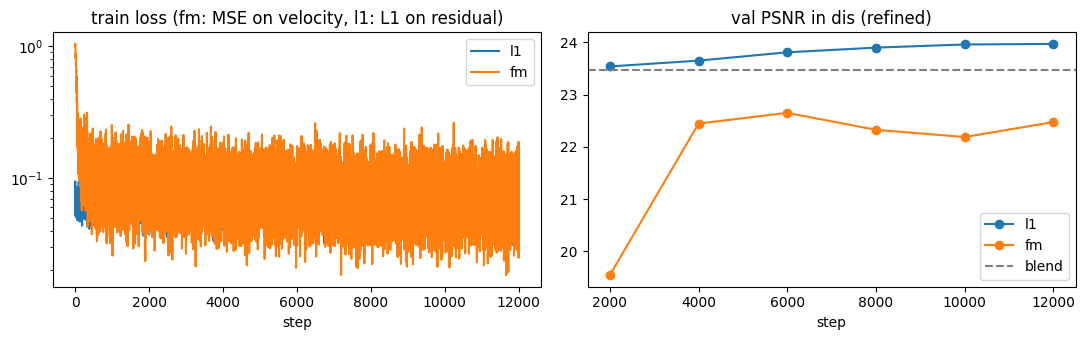

In [23]:
@torch.no_grad()
def cond_batch(u8, flows, idx, rng=None):
    a, t, b = frames_to_float(u8[idx])
    f01, f10 = flows[idx, 0].to(DEVICE), flows[idx, 1].to(DEVICE)
    if rng is not None and rng.random() < 0.5:
        a, b, f01, f10 = b, a, f10, f01
    Wd = make_warps(a, b, f01, f10)
    net.eval(); mask = net(make_features(Wd))
    bl = blend(Wd, mask); dis = dis_region(Wd)
    return refiner_cond(Wd, mask, bl, dis), (t - bl) / RES_SCALE, bl, t, dis

@torch.no_grad()
def refine(ref, mode, cond, n_samples=1, gen=None):
    if mode == "l1":
        return l1_predict(ref, cond)
    return torch.stack([fm_sample(ref, cond, FM_SAMPLE_STEPS, gen) for _ in range(n_samples)]).mean(0)

@torch.no_grad()
def val_refiner(ref, mode, n=32):
    ref.eval(); sse = {"blend": 0.0, "ref": 0.0}; npx = 0.0
    for i in range(0, min(n, N_VAL), 8):
        idx = torch.arange(i, min(i + 8, N_VAL))
        cond, x1, bl, t, dis = cond_batch(val_u8, val_flows, idx)
        out = (bl + RES_SCALE * refine(ref, mode, cond)).clamp(0, 1)
        sse["blend"] += float(((bl.clamp(0, 1) - t) ** 2 * dis).sum()); sse["ref"] += float(((out - t) ** 2 * dis).sum()); npx += float(dis.sum() * 3)
    return psnr_from_mse(sse["blend"] / max(npx, 1)), psnr_from_mse(sse["ref"] / max(npx, 1))

def train_refiner(mode):
    ref = RefinerUNet().to(DEVICE)
    opt_r = torch.optim.AdamW(ref.parameters(), lr=LR_FM, weight_decay=1e-4)
    sched_r = torch.optim.lr_scheduler.CosineAnnealingLR(opt_r, FM_STEPS)
    rng_r = np.random.default_rng(SEED + 1)
    hist_r, st = [], 0
    ck_path, final = WORK / f"ref_{mode}_latest.pt", WORK / f"ref_{mode}.pt"
    if RESUME and ck_path.exists():
        ck = torch.load(ck_path, map_location=DEVICE, weights_only=False)
        ref.load_state_dict(ck["net"]); opt_r.load_state_dict(ck["opt"]); sched_r.load_state_dict(ck["sched"]); hist_r, st = ck["hist"], ck["step"]
        rng_r = np.random.default_rng(SEED + 1 + st); print(mode, "resumed from", st)
    loss_fn = fm_loss if mode == "fm" else l1_loss
    t0 = time.time(); pbar = tqdm(total=FM_STEPS, initial=st, desc=f"refiner {mode}")
    while st < FM_STEPS:
        idx = torch.from_numpy(rng_r.choice(N_TRAIN, FM_BATCH, replace=False))
        cond, x1, _, _, dis = cond_batch(train_u8, train_flows, idx, rng_r)
        cond, x1 = dis_centered_crops([cond, x1], dis, FM_CROP, rng_r)
        if rng_r.random() < 0.5:
            cond, x1 = cond.flip(-1), x1.flip(-1)
        ref.train(); loss = loss_fn(ref, x1, cond)
        opt_r.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(ref.parameters(), 1.0); opt_r.step(); sched_r.step()
        st += 1; pbar.update(1); rec = {"step": st, "loss": float(loss.detach())}
        if st % FM_EVAL_EVERY == 0 or st == FM_STEPS:
            pb, pr = val_refiner(ref, mode); rec.update({"val_psnr_dis_blend": pb, "val_psnr_dis_ref": pr})
            pbar.set_postfix(loss=f"{np.mean([h['loss'] for h in hist_r[-200:]] + [rec['loss']]):.4f}", val_dis=f"{pb:.2f}->{pr:.2f}")
        hist_r.append(rec)
        if st % FM_CKPT_EVERY == 0:
            torch.save({"net": ref.state_dict(), "opt": opt_r.state_dict(), "sched": sched_r.state_dict(), "hist": hist_r, "step": st}, ck_path)
    pbar.close(); torch.save(ref.state_dict(), final)
    print(f"{mode}: {(time.time()-t0)/max(st,1)*1000:.0f} ms/step, final val PSNR(dis) blend->ref {hist_r[-1]['val_psnr_dis_blend']:.2f} -> {hist_r[-1]['val_psnr_dis_ref']:.2f}")
    ref.eval(); return ref, pd.DataFrame(hist_r)

print("refiner params", sum(p.numel() for p in RefinerUNet().parameters()))
refiners = {m: train_refiner(m) for m in REFINERS}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for m, (_, h) in refiners.items():
    h.plot(x="step", y="loss", ax=ax[0], label=m, title="train loss (fm: MSE on velocity, l1: L1 on residual)", logy=True)
    h.dropna(subset=["val_psnr_dis_ref"]).plot(x="step", y="val_psnr_dis_ref", ax=ax[1], label=m, marker="o", title="val PSNR in dis (refined)")
ax[1].axhline(refiners[REFINERS[0]][1].dropna(subset=["val_psnr_dis_blend"]).val_psnr_dis_blend.iloc[-1], ls="--", c="gray", label="blend")
ax[1].legend(); plt.tight_layout(); plt.savefig(WORK / "refiner_training.png", dpi=120); plt.show()

## Test pass: baselines + refiners, PSNR by region, LPIPS full-frame and on the densest-dis 128x128 window

In [24]:
lpips_fn = lpips.LPIPS(net="alex", verbose=False).to(DEVICE).eval()
WIN = 128

@torch.no_grad()
def lp(x, y):
    return lpips_fn(x.clamp(0, 1) * 2 - 1, y * 2 - 1).flatten()

@torch.no_grad()
def crop_win(x, wins):
    return torch.cat([x[i:i + 1, :, y0:y0 + WIN, x0:x0 + WIN] for i, (y0, x0) in enumerate(wins)], 0)

@torch.no_grad()
def test_batch(u8, keys):
    a, t, b = frames_to_float(u8)
    f01, f10 = estimate_flow(a, b), estimate_flow(b, a)
    Wd, preds, masks, regions = run_methods(a, t, b, f01, f10, net)
    bl, dis = preds["learned"], regions["dis"]
    cond = refiner_cond(Wd, masks["learned"], bl, dis)
    preds = {"fixed": preds["fixed"], "learned": bl, "oracle": preds["oracle"]}
    gen = torch.Generator(device=DEVICE).manual_seed(SEED + zlib.crc32(keys[0].encode()) % 10_000)
    samples = {}
    for mode, (ref, _) in refiners.items():
        if mode == "l1":
            r = refine(ref, "l1", cond); preds["l1"] = bl + RES_SCALE * r; preds["l1_dis"] = bl + RES_SCALE * r * dis
        else:
            ss = [fm_sample(ref, cond, FM_SAMPLE_STEPS, gen) for _ in range(FM_MEAN_SAMPLES)]
            samples["fm"] = ss
            preds["fm"] = bl + RES_SCALE * ss[0]; preds["fm_dis"] = bl + RES_SCALE * ss[0] * dis
            preds["fm_mean"] = bl + RES_SCALE * torch.stack(ss).mean(0)
    wins = best_dis_window(dis, WIN)
    return a, t, b, Wd, preds, regions, samples, wins

@torch.no_grad()
def eval_test(bs=4):
    rows, per = [], []
    for i in tqdm(range(0, N_TEST, bs), desc="test"):
        keys = test_keys[i:i + bs]
        u8 = torch.from_numpy(np.stack([test_get(j) for j in range(i, i + len(keys))])).permute(0, 1, 4, 2, 3)
        a, t, b, Wd, preds, regions, _, wins = test_batch(u8, keys)
        rows += [(keys[j], m, r, s, n) for (j, m, r, s, n) in region_sse(preds, t, regions)]
        tw = crop_win(t, wins)
        for j in range(len(keys)):
            per.append({"key": keys[j], "dis_frac": float(regions["dis"][j].mean()), "win_dis_frac": float(crop_win(regions["dis"], wins)[j].mean())})
        for m, p in preds.items():
            lf, lw = lp(p, t), lp(crop_win(p, wins), tw)
            for j in range(len(keys)):
                per[-len(keys) + j][f"psnr_{m}"] = psnr_from_mse(float(((p[j].clamp(0, 1) - t[j]) ** 2).mean()))
                per[-len(keys) + j][f"lpips_{m}"] = float(lf[j]); per[-len(keys) + j][f"lpipsw_{m}"] = float(lw[j])
    return pd.DataFrame(rows, columns=["key", "method", "region", "sse", "n"]), pd.DataFrame(per)

t0 = time.time()
test_df, test_per = eval_test()
print(f"test pass {time.time()-t0:.0f}s on {N_TEST} triplets")
test_df.to_csv(WORK / "fm_test_region_sse.csv", index=False); test_per.to_csv(WORK / "fm_test_per_triplet.csv", index=False)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 221MB/s]  


test:   0%|          | 0/250 [00:00<?, ?it/s]

test pass 2452s on 1000 triplets


## Results: PSNR by region vs `learned`, LPIPS paired deltas, PSNR/LPIPS trade-off

In [25]:
METHODS = [m for m in ["fixed", "learned", "l1", "l1_dis", "fm", "fm_dis", "fm_mean", "oracle"] if m in test_df.method.unique()]
NEW = [m for m in METHODS if m not in ("fixed", "learned")]
print(f"N_TEST={N_TEST}; dis share {test_per.dis_frac.mean():.3f}; dis share inside the 128 window {test_per.win_dis_frac.mean():.3f}")
tab = pd.DataFrame({r: {m: psnr_from_mse(pooled_mse(test_df, m, r)) for m in METHODS} for r in REGIONS})
tab["lpips_full"] = [test_per[f"lpips_{m}"].mean() for m in METHODS]
tab["lpips_win"] = [test_per[f"lpipsw_{m}"].mean() for m in METHODS]
print("pooled PSNR (dB) by region, mean LPIPS (lower is better):"); display(tab.round(4))

def mark(lo, hi, better_if_positive=True):
    s = 1 if better_if_positive else -1
    return "better" if s * lo > 0 else ("worse" if s * hi < 0 else "n.s.")

out = []
for r in REGIONS:
    bs = bootstrap_region(test_df, r, NEW, ref="learned", oracle="oracle", n_boot=2000, seed=SEED)
    for m in NEW:
        (d, dlo, dhi), (g, glo, ghi) = bs[m]["db"], bs[m]["G"]
        out.append({"region": r, "method": m, "delta_dB_vs_learned": d, "ci_lo": dlo, "ci_hi": dhi, "verdict": mark(dlo, dhi), "G_vs_learned": g, "G_lo": glo, "G_hi": ghi})
res = pd.DataFrame(out); display(res.round(4)); res.to_csv(WORK / "fm_results_psnr.csv", index=False)

rngb = np.random.default_rng(SEED); lrows = []
for col, name in (("lpips", "LPIPS full"), ("lpipsw", "LPIPS dis-window")):
    for m in NEW:
        d = (test_per[f"{col}_{m}"] - test_per[f"{col}_learned"]).to_numpy()
        boots = np.array([d[rngb.integers(0, len(d), len(d))].mean() for _ in range(2000)])
        lo, hi = np.percentile(boots, 2.5), np.percentile(boots, 97.5)
        lrows.append({"metric": name, "method": m, "delta_vs_learned": d.mean(), "ci_lo": lo, "ci_hi": hi, "verdict": mark(lo, hi, better_if_positive=False)})
lres = pd.DataFrame(lrows); display(lres.round(4)); lres.to_csv(WORK / "fm_results_lpips.csv", index=False)

print("trade-off (dis window): PSNR_dis vs LPIPS_win")
display(pd.DataFrame({"psnr_dis": tab["dis"], "lpips_win": tab["lpips_win"]}).round(4))
if "fm" in NEW and "fm_mean" in NEW:
    print("sample diversity: mean |fm - fm_mean| inside dis is the spread of the generative model;",
          f"PSNR fm_mean - fm in dis = {tab.loc['fm_mean','dis'] - tab.loc['fm','dis']:+.3f} dB, LPIPS_win fm_mean - fm = {tab.loc['fm_mean','lpips_win'] - tab.loc['fm','lpips_win']:+.4f}")

N_TEST=1000; dis share 0.071; dis share inside the 128 window 0.210
pooled PSNR (dB) by region, mean LPIPS (lower is better):


,full,dis,occ,lpips_full,lpips_win
fixed,30.8131,21.1287,23.8299,0.0434,0.0745
learned,31.0910,21.5515,24.3895,0.0395,0.0645
l1,31.4698,21.9110,24.7409,0.0321,0.0611
l1_dis,31.3182,21.9110,24.7179,0.0386,0.0647
fm,29.9520,20.2705,23.2032,0.0405,0.0762
fm_dis,30.2271,20.2705,23.3857,0.0430,0.0769
fm_mean,31.0062,21.4362,24.3369,0.0360,0.0672
oracle,34.1391,26.3277,28.5797,0.0236,0.0383


,region,method,delta_dB_vs_learned,ci_lo,ci_hi,verdict,G_vs_learned,G_lo,G_hi
0,full,l1,0.3788,0.3553,0.4029,better,0.1656,0.1559,0.1759
1,full,l1_dis,0.2272,0.2104,0.2436,better,0.1011,0.0949,0.1074
2,full,fm,-1.1390,-1.1949,-1.0851,worse,-0.5946,-0.6283,-0.5635
3,full,fm_dis,-0.8640,-0.9087,-0.8209,worse,-0.4364,-0.4612,-0.4132
4,full,fm_mean,-0.0849,-0.1113,-0.0612,worse,-0.0391,-0.0514,-0.0281
5,full,oracle,3.0480,2.9531,3.1456,better,1.0000,1.0000,1.0000
6,dis,l1,0.3595,0.3351,0.3844,better,0.1191,0.1117,0.1265
7,dis,l1_dis,0.3595,0.3351,0.3844,better,0.1191,0.1117,0.1265
8,dis,fm,-1.2810,-1.3418,-1.2204,worse,-0.5143,-0.5456,-0.4852
9,dis,fm_dis,-1.2810,-1.3418,-1.2204,worse,-0.5143,-0.5456,-0.4852


,metric,method,delta_vs_learned,ci_lo,ci_hi,verdict
0,LPIPS full,l1,-0.0074,-0.0079,-0.0068,better
1,LPIPS full,l1_dis,-0.0009,-0.0011,-0.0008,better
2,LPIPS full,fm,0.0010,0.0003,0.0018,worse
3,LPIPS full,fm_dis,0.0035,0.0030,0.0040,worse
4,LPIPS full,fm_mean,-0.0035,-0.0040,-0.0029,better
5,LPIPS full,oracle,-0.0159,-0.0165,-0.0154,better
6,LPIPS dis-window,l1,-0.0034,-0.0042,-0.0025,better
7,LPIPS dis-window,l1_dis,0.0002,-0.0003,0.0007,better
8,LPIPS dis-window,fm,0.0117,0.0100,0.0135,worse
9,LPIPS dis-window,fm_dis,0.0124,0.0109,0.0141,worse


trade-off (dis window): PSNR_dis vs LPIPS_win


,psnr_dis,lpips_win
fixed,21.1287,0.0745
learned,21.5515,0.0645
l1,21.9110,0.0611
l1_dis,21.9110,0.0647
fm,20.2705,0.0762
fm_dis,20.2705,0.0769
fm_mean,21.4362,0.0672
oracle,26.3277,0.0383


sample diversity: mean |fm - fm_mean| inside dis is the spread of the generative model; PSNR fm_mean - fm in dis = +1.166 dB, LPIPS_win fm_mean - fm = -0.0091


## Visualization: densest-dis windows, two FM samples next to the L1 regressor

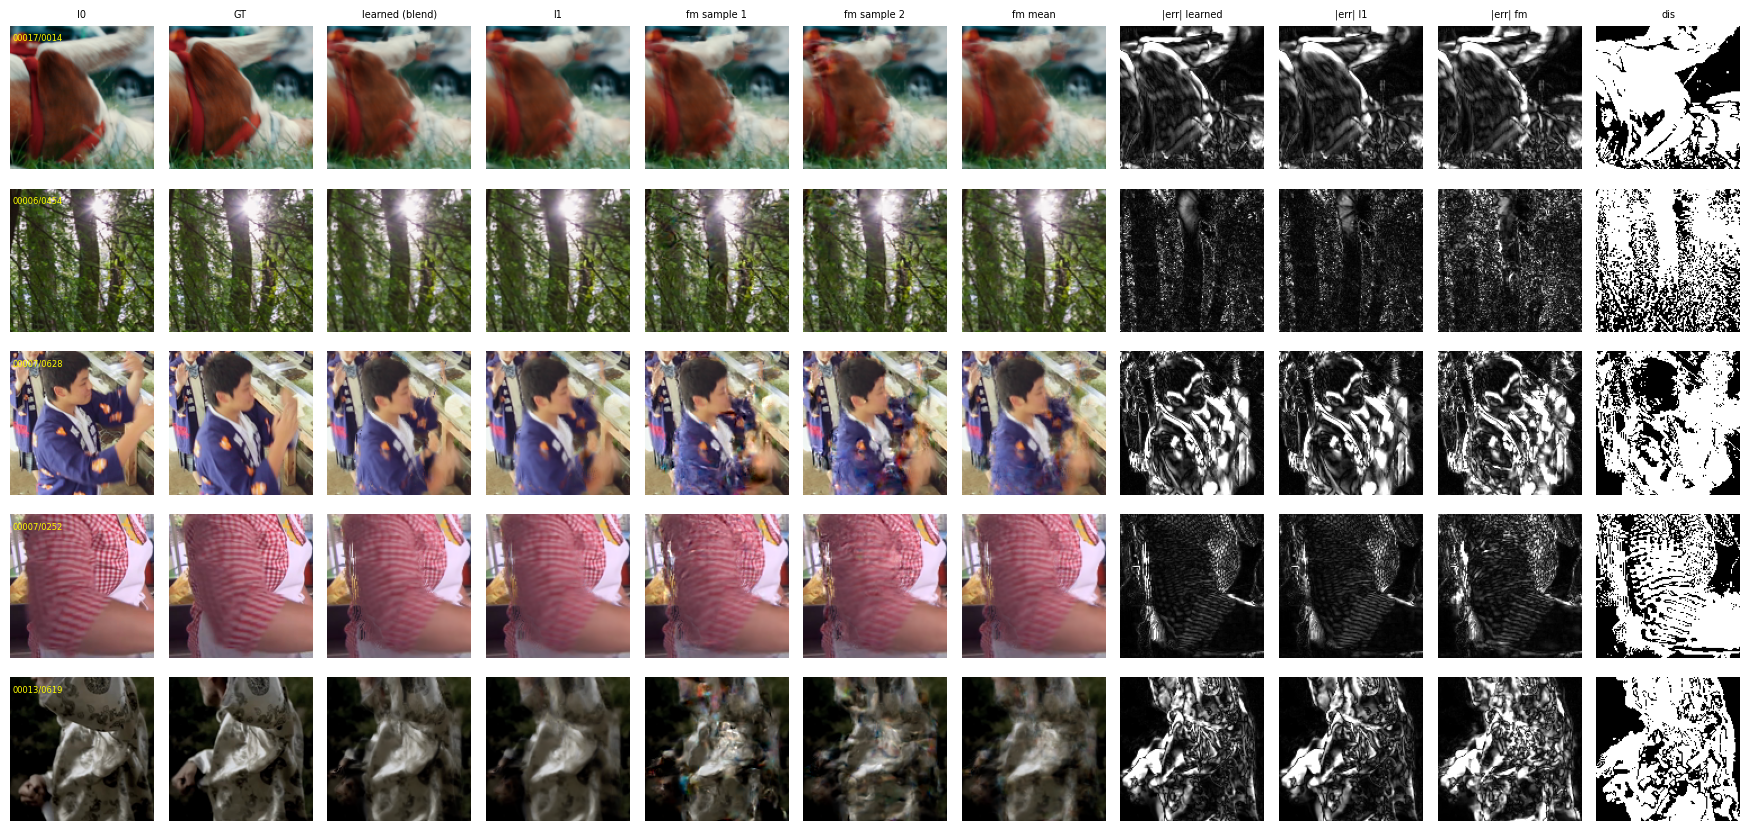

In [26]:
top = test_per.sort_values("win_dis_frac", ascending=False).head(5)
cols = ["I0", "GT", "learned (blend)", "l1", "fm sample 1", "fm sample 2", "fm mean", "|err| learned", "|err| l1", "|err| fm", "dis"]
fig, axes = plt.subplots(len(top), len(cols), figsize=(1.6 * len(cols), 1.7 * len(top)))
with torch.no_grad():
    for row, (_, rec) in enumerate(top.iterrows()):
        j = test_keys.index(rec.key)
        u8 = torch.from_numpy(test_get(j)[None]).permute(0, 1, 4, 2, 3)
        a, t, b, Wd, preds, regions, samples, wins = test_batch(u8, [rec.key])
        W_ = lambda x: crop_win(x, wins)
        s2 = preds["learned"] + RES_SCALE * samples["fm"][1] if "fm" in samples and len(samples["fm"]) > 1 else preds.get("fm", preds["learned"])
        img = lambda x: W_(x)[0].clamp(0, 1).permute(1, 2, 0).cpu().numpy()
        err = lambda x: (W_(x) - W_(t)).abs().mean(1)[0].cpu().numpy() * 4
        panels = [img(a), img(t), img(preds["learned"]), img(preds.get("l1", preds["learned"])), img(preds.get("fm", preds["learned"])), img(s2),
                  img(preds.get("fm_mean", preds["learned"])), err(preds["learned"]), err(preds.get("l1", preds["learned"])), err(preds.get("fm", preds["learned"])),
                  W_(regions["dis"])[0, 0].cpu().numpy()]
        for c, (ax, p) in enumerate(zip(axes[row], panels)):
            ax.imshow(p, cmap=None if p.ndim == 3 else "gray", vmin=0, vmax=1); ax.axis("off")
            if row == 0: ax.set_title(cols[c], fontsize=7)
        axes[row, 0].text(2, 12, f"{rec.key}", color="yellow", fontsize=6)
plt.tight_layout(); plt.savefig(WORK / "fm_qualitative.png", dpi=140); plt.show()

## What to report

1. Baseline numbers (`fixed`, `learned`) on this test subset, then the refiners: PSNR by region with CI vs `learned`,
   LPIPS full and on the dis window with CI. Say which predictions above held and which did not.
2. The PSNR/LPIPS trade-off table: regression (`l1`) vs one generative sample (`fm`) vs averaged samples (`fm_mean`).
3. `fm_qualitative.png`: two samples of the same window show what the generative model is uncertain about.
4. `fm_dis` vs `fm`: whether the refiner changes pixels outside `dis`.
5. Same net, same crops, same steps for both modes; one seed; `TEST_LIMIT` triplets of the official test; 20 Euler steps.